In [1]:
import pandas as pd 


In [2]:
products = pd.read_csv("products_clean.csv")
products["price"].dtype     # should say float64

dtype('float64')

In [3]:
sales = pd.read_csv("sales_raw.csv")
sales

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue
0,5123656,2025-12-18,3,SK10002,NaN,23.0,0,0,0,48.30
1,5089163,2025-06-03,4,SK10010,NaN,9.0,0,0,0,27.00
2,5036031,2024-07-29,1,SK10014,NaN,4.0,0,0,0,19.00
3,5168458,2026-09-04,1,SK10021,NaN,7.0,0,0,0,22.40
4,5156412,2026-06-25,3,SK10012,NaN,25.0,0,0,0,50.00
...,...,...,...,...,...,...,...,...,...,...
173667,5066456,2025-01-21,6,SK10026,12,1.0,0,1,0,17.50
173668,5053460,2024-11-09,4,SK10018,NaN,11.0,0,0,0,46.75
173669,5010743,2024-03-07,6,SK10010,NaN,12.0,0,0,0,36.00
173670,5049690,2024-10-19,3,SK10009,NaN,49.0,0,0,0,53.90


In [4]:
sales.describe()


,transaction_line_id,units_sold,on_promo,on_markdown,units_returned,revenue
count,1.736720e+05,173152.000000,173672.000000,173672.000000,173672.000000,173325.000000
mean,5.086476e+06,11.042292,0.053791,0.028110,0.050261,35.207224
std,4.993183e+04,26.610626,0.225606,0.165289,0.259158,27.435325
min,5.000001e+06,-62.000000,0.000000,0.000000,0.000000,0.780000
25%,5.043230e+06,4.000000,0.000000,0.000000,0.000000,16.650000
50%,5.086460e+06,9.000000,0.000000,0.000000,0.000000,28.120000
75%,5.129717e+06,15.000000,0.000000,0.000000,0.000000,45.000000
max,5.172981e+06,4200.000000,1.000000,1.000000,7.000000,660.000000


In [5]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 173672 entries, 0 to 173671
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   transaction_line_id  173672 non-null  int64  
 1   date                 173672 non-null  str    
 2   store_id             173672 non-null  str    
 3   sku                  173672 non-null  str    
 4   size                 19305 non-null   str    
 5   units_sold           173152 non-null  float64
 6   on_promo             173672 non-null  int64  
 7   on_markdown          173672 non-null  int64  
 8   units_returned       173672 non-null  int64  
 9   revenue              173325 non-null  float64
dtypes: float64(2), int64(4), str(4)
memory usage: 16.3 MB


In [6]:
sales.duplicated(subset = ["transaction_line_id"]).sum()

np.int64(691)

In [7]:
sales[sales.duplicated(subset = ["transaction_line_id"],keep = False)].sort_values("transaction_line_id")

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue
112466,5000098,2024-01-01,4,SK10015,NaN,3.0,0,0,0,12.00
59171,5000098,2024-01-01,4,SK10015,NaN,3.0,0,0,0,12.00
17413,5000677,2024-01-05,1,SK10004,NaN,7.0,0,0,0,13.65
131339,5000677,2024-01-05,1,SK10004,NaN,7.0,0,0,0,13.65
138005,5000716,2024-01-05,2,SK10011,NaN,14.0,0,0,0,25.90
...,...,...,...,...,...,...,...,...,...,...
113097,5172103,2026-09-25,4,SK10021,NaN,5.0,0,0,0,16.00
117211,5172743,2026-09-29,3,SK10033,One size,3.0,0,0,0,30.00
30211,5172743,2026-09-29,3,SK10033,One size,3.0,0,0,0,30.00
93947,5172843,2026-09-30,1,SK10018,NaN,8.0,0,0,0,34.00


In [8]:
sales.duplicated().sum()

np.int64(691)

In [9]:
(~sales["date"].str.match(r"^\d{4}-\d{2}-\d{2}$")).sum()

np.int64(521)

In [10]:
sales[(~sales["date"].str.match(r"^\d{4}-\d{2}-\d{2}$"))]

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue
49,5172521,28/09/2026,1,SK10022,NaN,10.0,0,0,0,15.00
278,5110414,05/10/2025,2,SK10015,NaN,6.0,0,0,0,24.00
496,5074937,14/03/2025,3,SK10005,NaN,17.0,0,0,0,44.20
956,5026683,07/06/2024,1,SK10004,NaN,11.0,0,0,0,21.45
1465,5142288,06/04/2026,3,SK10014,NaN,15.0,0,0,0,71.25
...,...,...,...,...,...,...,...,...,...,...
172129,5075542,17/03/2025,6,SK10004,NaN,23.0,0,0,0,44.85
172383,5145384,24/04/2026,2,SK10021,NaN,13.0,1,0,0,33.28
172668,5038284,12/08/2024,2,SK10008,NaN,12.0,0,0,0,23.61
173043,5073124,03/03/2025,6,SK10009,NaN,20.0,0,0,0,22.00


In [11]:
sales["store_id"].value_counts()

store_id
6          37103
3          35417
1          31894
2          23225
4          23103
5          22843
Store 6       20
Store 4       18
Store 1       16
Store 3       13
Store 2       12
Store 5        8
Name: count, dtype: int64

In [12]:
(~sales["sku"].str.match(r"^SK\d{5}$")).sum()

np.int64(346)

In [13]:
sales[(~sales["sku"].str.match(r"^SK\d{5}$"))]

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue
485,5093724,2025-06-28,6,sk10037,NaN,18.0,0,0,1,63.00
519,5111405,2025-10-10,6,SK10023,NaN,10.0,0,0,0,27.50
899,5042084,2024-09-05,3,SK1O012,NaN,11.0,0,0,0,22.00
907,5094347,2025-07-02,3,SK1O027,14,1.0,0,1,0,31.50
1250,5078578,2025-04-04,2,SK1O019,NaN,10.0,0,0,0,45.00
...,...,...,...,...,...,...,...,...,...,...
171509,5167153,2026-08-27,1,SK1O008,NaN,15.0,0,0,0,32.62
171518,5169576,2026-09-10,5,SK10003,NaN,4.0,0,0,0,15.00
172602,5124959,2025-12-26,3,SK10011,NaN,6.0,0,0,0,11.10
173477,5128232,2026-01-13,6,sk10003,NaN,22.0,0,0,0,82.50


In [14]:
lower_case = sales["sku"].str.match(r"^sk\d{5}$").sum()

In [15]:
lower_case

np.int64(124)

In [16]:
letter_o = sales["sku"].str.contains("O").sum()

In [17]:
letter_o

np.int64(101)

In [18]:
hidden_spaces = sales["sku"] != sales["sku"].str.strip()

In [19]:
hidden_spaces.sum()

np.int64(121)

In [20]:
124+101+121

346

In [21]:
sales["units_sold"].describe()

count    173152.000000
mean         11.042292
std          26.610626
min         -62.000000
25%           4.000000
50%           9.000000
75%          15.000000
max        4200.000000
Name: units_sold, dtype: float64

In [22]:
sales["units_sold"].isna().sum()


np.int64(520)

In [23]:
sales[sales["units_sold"].isna()]

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue
55,5056576,2024-11-26,6,SK10025,14,NaN,0,0,1,79.00
1335,5058546,2024-12-07,5,SK10016,NaN,NaN,0,0,0,32.30
1598,5148849,2026-05-13,5,SK10022,NaN,NaN,0,0,0,7.50
1685,5027529,2024-06-11,6,SK10004,NaN,NaN,0,0,0,48.75
2435,5153015,2026-06-06,1,SK10028,8,NaN,0,0,0,50.00
...,...,...,...,...,...,...,...,...,...,...
171056,5012234,2024-03-16,3,SK10010,NaN,NaN,0,0,0,51.00
171524,5088441,2025-05-30,3,SK10038,NaN,NaN,0,0,0,30.00
172251,5005223,2024-02-02,1,SK10004,NaN,NaN,0,0,0,23.40
172506,5064986,2025-01-13,5,SK10011,NaN,NaN,0,0,0,5.55


In [24]:
sales["units_sold"].nlargest(10)

16575     4200.0
70293     2600.0
112177    2600.0
96457     2500.0
112761    2300.0
122032    2200.0
45516     2100.0
100452    2100.0
130885    2100.0
172597    2100.0
Name: units_sold, dtype: float64

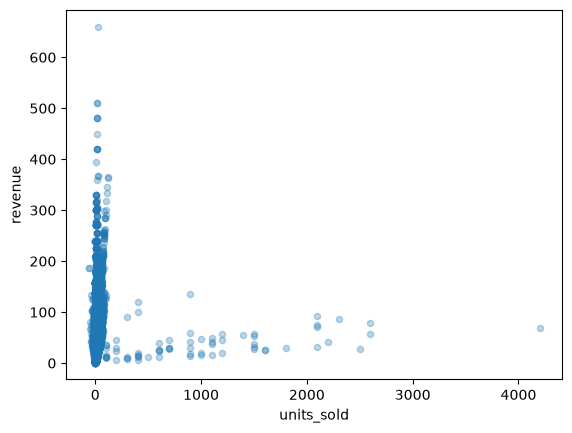

In [25]:
import matplotlib.pyplot as plt
sales.plot(kind="scatter", x="units_sold", y="revenue", alpha=0.3)
plt.show()

Units sold: extreme values

What I checked: a summary of units_sold (describe), the 10 largest values, and a scatter chart of units sold against revenue.

What I found:

A typical sale is 4–15 units (median 9), but the maximum is 4,200.
The 10 largest values (2,100–4,200) all end in “00”.
On the chart, these rows have huge units but normal revenue (£10–£130). If 4,200 items had really been sold, revenue would be in the thousands.

Conclusion: the revenue is correct and the units were typed with two extra zeros (e.g. 42 entered as 4,200). This is a keying error, not real demand.

Next: find every affected row with a rule (revenue ÷ units far below the product’s price), then divide those units by 100.

In [26]:
sales.nlargest(5, "revenue")

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue
104263,5124165,2025-12-20,6,SK10035,NaN,22.0,0,0,0,660.0
22396,5124350,2025-12-21,6,SK10035,NaN,17.0,0,0,0,510.0
110061,5121692,2025-12-07,3,SK10035,NaN,17.0,0,0,0,510.0
52933,5061134,2024-12-21,6,SK10035,NaN,16.0,0,0,2,480.0
91337,5124891,2025-12-24,6,SK10035,NaN,16.0,0,0,0,480.0


In [27]:
top5 = sales.nlargest(5, "revenue")
top5 = top5.merge(products[["sku", "product_name", "price"]], on="sku", how="left")
top5["units_x_price"] = top5["units_sold"] * top5["price"]
top5[["sku", "product_name", "units_sold", "price", "units_x_price", "revenue"]]

,sku,product_name,units_sold,price,units_x_price,revenue
0,SK10035,Eau De Parfum 100ml,22.0,30.0,660.0,660.0
1,SK10035,Eau De Parfum 100ml,17.0,30.0,510.0,510.0
2,SK10035,Eau De Parfum 100ml,17.0,30.0,510.0,510.0
3,SK10035,Eau De Parfum 100ml,16.0,30.0,480.0,480.0
4,SK10035,Eau De Parfum 100ml,16.0,30.0,480.0,480.0


Highest revenue check: the top 5 revenue rows (£480–£660) are real sales: Eau De Parfum (£30) in the week before Christmas, mainly at City Centre. Units × price matches revenue exactly, so no fix is needed.

In [28]:
sales[sales["revenue"] < 0]

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue


In [29]:
(sales["units_sold"] < 0).sum()

np.int64(345)

In [30]:
neg = sales[sales["units_sold"] < 0]

In [31]:


neg

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue
393,5116475,2025-11-08,4,SK10015,NaN,-6.0,0,0,0,24.00
669,5089876,2025-06-07,3,SK10039,NaN,-3.0,0,0,0,36.00
1750,5028736,2024-06-18,4,SK10007,NaN,-6.0,0,0,0,9.30
1948,5055856,2024-11-23,1,SK10008,NaN,-15.0,0,0,0,32.62
2137,5062578,2024-12-31,1,SK10018,NaN,-7.0,0,0,0,29.75
...,...,...,...,...,...,...,...,...,...,...
170181,5127904,2026-01-11,6,SK10026,18,-3.0,0,1,0,52.50
170312,5007498,2024-02-16,4,SK10021,NaN,-4.0,0,0,0,12.80
171066,5163428,2026-08-03,1,SK10020,NaN,-10.0,1,0,0,18.40
172957,5125281,2025-12-28,2,SK10008,NaN,-9.0,0,0,0,20.25


In [32]:
products.head()

,sku,product_name,category,department,price,cost_price,shelf_life_days,case_size,season
0,SK10001,Semi Skimmed Milk 2.272L,Dairy,Food,1.65,1.10,3.0,6.0,NaN
1,SK10002,Free Range Eggs 6pk,Dairy,Food,2.10,1.30,14.0,6.0,NaN
2,SK10003,Mature Cheddar 400g,Dairy,Food,3.75,2.20,21.0,6.0,NaN
3,SK10004,Greek Style Yoghurt 500g,Dairy,Food,1.95,1.15,4.0,6.0,NaN
4,SK10005,Salted Butter 250g,Dairy,Food,2.60,1.70,30.0,10.0,NaN


we want to know whether the minus sign is just a typing mistake (the real sale was positive) or something else, like a return.

In [33]:
result = neg.merge(

    products[["sku", "product_name", "price"]],

    on = "sku",

    how = "left"
)

In [34]:
result

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue,product_name,price
0,5116475,2025-11-08,4,SK10015,NaN,-6.0,0,0,0,24.00,Smoked Salmon 100g,4.00
1,5089876,2025-06-07,3,SK10039,NaN,-3.0,0,0,0,36.00,Scented Candle 200g,12.00
2,5028736,2024-06-18,4,SK10007,NaN,-6.0,0,0,0,9.30,Wholemeal Bread 800g,1.55
3,5055856,2024-11-23,1,SK10008,NaN,-15.0,0,0,0,32.62,Croissants 4pk,2.25
4,5062578,2024-12-31,1,SK10018,NaN,-7.0,0,0,0,29.75,Lasagne Ready Meal 400g,4.25
...,...,...,...,...,...,...,...,...,...,...,...,...
340,5127904,2026-01-11,6,SK10026,18,-3.0,0,1,0,52.50,Womens Knitted Jumper,35.00
341,5007498,2024-02-16,4,SK10021,NaN,-4.0,0,0,0,12.80,Sparkling Water 6 x 500ml,3.20
342,5163428,2026-08-03,1,SK10020,NaN,-10.0,1,0,0,18.40,Orange Juice 1L,2.30
343,5125281,2025-12-28,2,SK10008,NaN,-9.0,0,0,0,20.25,Croissants 4pk,2.25


Negative units: 345 rows have negative units, but none has negative revenue. Comparing with price, units × price (ignoring the minus) matches revenue, allowing for promotions (20% off) and markdowns (30–50% off). Conclusion: the minus sign was typed by mistake, and these are real sales. Fix: make the units positive.

In [35]:
check = sales.merge(

    products[["sku","price"]],
    on = "sku",
    how ="left"
)

In [36]:
check 

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue,price
0,5123656,2025-12-18,3,SK10002,NaN,23.0,0,0,0,48.30,2.10
1,5089163,2025-06-03,4,SK10010,NaN,9.0,0,0,0,27.00,3.00
2,5036031,2024-07-29,1,SK10014,NaN,4.0,0,0,0,19.00,4.75
3,5168458,2026-09-04,1,SK10021,NaN,7.0,0,0,0,22.40,3.20
4,5156412,2026-06-25,3,SK10012,NaN,25.0,0,0,0,50.00,2.00
...,...,...,...,...,...,...,...,...,...,...,...
173667,5066456,2025-01-21,6,SK10026,12,1.0,0,1,0,17.50,35.00
173668,5053460,2024-11-09,4,SK10018,NaN,11.0,0,0,0,46.75,4.25
173669,5010743,2024-03-07,6,SK10010,NaN,12.0,0,0,0,36.00,3.00
173670,5049690,2024-10-19,3,SK10009,NaN,49.0,0,0,0,53.90,1.10


In [37]:
check["implied_price"]= (check["revenue"]/check["units_sold"]) 

In [38]:
check

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue,price,implied_price
0,5123656,2025-12-18,3,SK10002,NaN,23.0,0,0,0,48.30,2.10,2.10
1,5089163,2025-06-03,4,SK10010,NaN,9.0,0,0,0,27.00,3.00,3.00
2,5036031,2024-07-29,1,SK10014,NaN,4.0,0,0,0,19.00,4.75,4.75
3,5168458,2026-09-04,1,SK10021,NaN,7.0,0,0,0,22.40,3.20,3.20
4,5156412,2026-06-25,3,SK10012,NaN,25.0,0,0,0,50.00,2.00,2.00
...,...,...,...,...,...,...,...,...,...,...,...,...
173667,5066456,2025-01-21,6,SK10026,12,1.0,0,1,0,17.50,35.00,17.50
173668,5053460,2024-11-09,4,SK10018,NaN,11.0,0,0,0,46.75,4.25,4.25
173669,5010743,2024-03-07,6,SK10010,NaN,12.0,0,0,0,36.00,3.00,3.00
173670,5049690,2024-10-19,3,SK10009,NaN,49.0,0,0,0,53.90,1.10,1.10


In [39]:
check[check["implied_price"] < check["price"]*0.05]

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue,price,implied_price
393,5116475,2025-11-08,4,SK10015,NaN,-6.0,0,0,0,24.00,4.00,-4.000000
669,5089876,2025-06-07,3,SK10039,NaN,-3.0,0,0,0,36.00,12.00,-12.000000
1750,5028736,2024-06-18,4,SK10007,NaN,-6.0,0,0,0,9.30,1.55,-1.550000
1948,5055856,2024-11-23,1,SK10008,NaN,-15.0,0,0,0,32.62,2.25,-2.174667
2137,5062578,2024-12-31,1,SK10018,NaN,-7.0,0,0,0,29.75,4.25,-4.250000
...,...,...,...,...,...,...,...,...,...,...,...,...
171066,5163428,2026-08-03,1,SK10020,NaN,-10.0,1,0,0,18.40,2.30,-1.840000
172597,5039531,2024-08-20,2,SK10017,NaN,2100.0,1,0,0,75.60,4.50,0.036000
172957,5125281,2025-12-28,2,SK10008,NaN,-9.0,0,0,0,20.25,2.25,-2.250000
173207,5136979,2026-03-07,1,SK10012,NaN,1000.0,0,0,0,20.00,2.00,0.020000


In [40]:
((check["implied_price"] < check["price"]*0.05)  & (check["units_sold"] > 0)).sum()

np.int64(67)

×100 keying errors: 67 rows where the price paid per item (revenue ÷ units) is less than 5% of the product’s price, e.g. 2,100 salad bowls for £75.60 (3.6p each). The revenue is normal and the units are 100 times too big. Fix: divide those units by 100. (One more such row has a badly typed SKU and will show up after the SKUs are fixed.)

units_sold is fully inspected: 520 blanks, 345 negatives, 67 ×100 errors. 

In [41]:
sales["on_promo"].value_counts()

on_promo
0    164330
1      9342
Name: count, dtype: int64

In [42]:
sales["on_markdown"].value_counts()

on_markdown
0    168790
1      4882
Name: count, dtype: int64

In [43]:
sales["units_returned"].describe()

count    173672.000000
mean          0.050261
std           0.259158
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           7.000000
Name: units_returned, dtype: float64

In [44]:
sales["revenue"].isna().sum()

np.int64(347)

In [45]:
(sales["units_returned"] > sales["units_sold"]).sum()

np.int64(345)

345 rows show returns greater than units sold. These are the same 345 rows with negative units (0 returns > a negative number). Not a separate problem. Re-check after fixing the negative units: it should be 0.

In [46]:
size_check = sales.merge(

    products[["sku","department"]],
    on = "sku",
    how ="left"
)

In [47]:
size_check 

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue,department
0,5123656,2025-12-18,3,SK10002,NaN,23.0,0,0,0,48.30,Food
1,5089163,2025-06-03,4,SK10010,NaN,9.0,0,0,0,27.00,Food
2,5036031,2024-07-29,1,SK10014,NaN,4.0,0,0,0,19.00,Food
3,5168458,2026-09-04,1,SK10021,NaN,7.0,0,0,0,22.40,Food
4,5156412,2026-06-25,3,SK10012,NaN,25.0,0,0,0,50.00,Food
...,...,...,...,...,...,...,...,...,...,...,...
173667,5066456,2025-01-21,6,SK10026,12,1.0,0,1,0,17.50,Clothing
173668,5053460,2024-11-09,4,SK10018,NaN,11.0,0,0,0,46.75,Food
173669,5010743,2024-03-07,6,SK10010,NaN,12.0,0,0,0,36.00,Food
173670,5049690,2024-10-19,3,SK10009,NaN,49.0,0,0,0,53.90,Food


In [48]:
size_check[size_check["size"].notna()]

,transaction_line_id,date,store_id,sku,size,units_sold,on_promo,on_markdown,units_returned,revenue,department
13,5052836,2024-11-06,1,SK10032,5-6,1.0,0,0,0,14.0,Clothing
18,5015884,2024-04-06,3,SK10029,36,2.0,0,0,1,60.0,Clothing
37,5024656,2024-05-26,3,SK10029,30,1.0,0,0,1,30.0,Clothing
45,5028979,2024-06-19,6,SK10033,One size,2.0,0,0,1,20.0,Clothing
54,5015100,2024-04-01,6,SK10028,12,1.0,0,0,0,25.0,Clothing
...,...,...,...,...,...,...,...,...,...,...,...
173646,5156998,2026-06-28,3,SK10027,16,1.0,0,1,1,31.5,Clothing
173647,5110272,2025-10-04,3,SK10032,5-6,1.0,0,0,0,14.0,Clothing
173651,5060216,2024-12-16,6,SK10032,5-6,1.0,0,0,0,14.0,Clothing
173655,5120704,2025-12-02,1,SK10031,L,1.0,0,0,0,69.0,Clothing


In [49]:
size_check["department"].value_counts(dropna=False)

department
Food        138707
Clothing     19262
Beauty       10610
Home          4747
NaN            346
Name: count, dtype: int64

In [50]:
has_size = size_check[size_check["size"].notna()]

In [51]:
has_size["department"].value_counts(dropna=False)

department
Clothing    19262
NaN            43
Name: count, dtype: int64

In [52]:
sales = sales.drop_duplicates(

    subset = ["transaction_line_id"]
)

In [53]:
sales.duplicated(subset = ["transaction_line_id"]).sum()

np.int64(0)

In [54]:
sales.shape

(172981, 10)

In [55]:
sales["sku"] = sales["sku"].str.strip().str.upper()

In [56]:
sales["sku"] = sales["sku"].str.replace(r"O","0",regex = False)

In [57]:
sales["sku"].str.match(r"^SK\d{5}$").sum()

np.int64(172981)

In [58]:

(~sales["sku"].str.match(r"^SK\d{5}$")).sum()


np.int64(0)

In [59]:
sales["store_id"].value_counts()

store_id
6          36955
3          35263
1          31757
2          23140
4          23020
5          22760
Store 6       20
Store 4       17
Store 1       16
Store 3       13
Store 2       12
Store 5        8
Name: count, dtype: int64

In [60]:
sales["store_id"]=sales["store_id"].str.extract(r"(\d+)")[0].astype(int)


In [61]:
sales["store_id"].value_counts()

store_id
6    36975
3    35276
1    31773
2    23152
4    23037
5    22768
Name: count, dtype: int64

In [62]:
sales["store_id"].dtype

dtype('int64')

In [63]:
(~sales["sku"].isin(products["sku"]) ).sum()

np.int64(0)

In [64]:
iso = pd.to_datetime(sales["date"],format ="%Y-%m-%d",errors="coerce") 

In [65]:
uk = pd.to_datetime(sales["date"],format ="%d/%m/%Y",errors="coerce") 

In [66]:
sales["date"] = iso.fillna(uk)

In [67]:
sales["date"]

0        2025-12-18
1        2025-06-03
2        2024-07-29
3        2026-09-04
4        2026-06-25
            ...    
173667   2025-01-21
173668   2024-11-09
173669   2024-03-07
173670   2024-10-19
173671   2024-12-24
Name: date, Length: 172981, dtype: datetime64[us]

In [68]:
sales["date"].isna().sum()

np.int64(0)

In [69]:
sales["date"].min()

Timestamp('2024-01-01 00:00:00')

In [70]:
sales["date"].max()

Timestamp('2026-09-30 00:00:00')

In [71]:
neg = sales["units_sold"] < 0

In [72]:
neg.sum()

np.int64(345)

In [73]:
sales.loc[neg, "units_sold"] = -sales.loc[neg, "units_sold"]

In [74]:
(sales["units_returned"] > sales["units_sold"]).sum()

np.int64(0)

In [75]:
sales = sales.merge(products[["sku", "price"]], on="sku", how="left")
sales["implied_price"] = sales["revenue"] / sales["units_sold"]

In [76]:
x100 = (sales["implied_price"] < sales["price"] * 0.05) & (sales["units_sold"] > 0)
x100.sum()        

np.int64(68)

In [77]:
sales.loc[x100, "units_sold"] = sales.loc[x100, "units_sold"] / 100

In [78]:
sales.loc[x100, "units_sold"]

2914      15.0
4669       9.0
8713       1.0
12035      4.0
16335     12.0
          ... 
157003    11.0
161164     2.0
169306     4.0
171916    21.0
172522    10.0
Name: units_sold, Length: 68, dtype: float64

In [79]:
sales["units_sold"].max()

np.float64(122.0)

In [80]:
sales.nlargest(5, "units_sold")[["date", "store_id", "sku", "units_sold", "revenue", "price"]]

,date,store_id,sku,units_sold,revenue,price
65305,2024-12-24,6,SK10024,122.0,366.0,3.0
109964,2025-12-24,6,SK10024,121.0,363.0,3.0
101099,2025-12-19,6,SK10024,115.0,345.0,3.0
115464,2025-12-23,6,SK10024,111.0,333.0,3.0
139366,2024-12-23,6,SK10024,106.0,318.0,3.0


Largest units after the fix (106–122) are real: Mince Pies at City Centre in the days before Christmas. Units × price matches revenue.

In [81]:
sales["implied_price"] = sales["revenue"] / sales["units_sold"]
x100 = (sales["implied_price"] < sales["price"] * 0.05) & (sales["units_sold"] > 0)
x100.sum()

np.int64(0)

In [82]:
sales = sales.dropna(subset=["units_sold"])

In [83]:
sales["revenue_estimated"] = sales["revenue"].isna().astype(int)

In [84]:
sales["revenue"] = sales["revenue"].fillna(sales["units_sold"] * sales["price"])

In [85]:
sales["units_sold"].isna().sum()

np.int64(0)

In [86]:
sales["revenue"].isna().sum()

np.int64(0)

In [87]:
sales["revenue_estimated"].sum()

np.int64(344)

In [88]:
sales.shape

(172463, 13)

In [89]:
sales = sales.drop(columns=["price", "implied_price"])
sales["units_sold"] = sales["units_sold"].astype(int)
sales = sales.reset_index(drop=True)

print(sales.shape)        
sales.to_csv("sales_clean.csv", index=False)

(172463, 11)


In [92]:
sales.isna().sum()

transaction_line_id         0
date                        0
store_id                    0
sku                         0
size                   153304
units_sold                  0
on_promo                    0
on_markdown                 0
units_returned              0
revenue                     0
revenue_estimated           0
dtype: int64